# Unfallatlas 2025: Augmenting the Data with Educated Guesses

The ensembles in `tiziano_ensembles.ipynb` all stop at about the same score (Brier skill ≈ 0.074). More training data
barely helps, so the limit is the **information** in the features, not the model. The outcome mostly depends on things the
Unfallatlas does not record: **speed, road type, helmet use and seatbelt use**.

**Experiment:** add educated guesses for these four quantities and retrain the tuned hist gradient boosting model.

**Where the guesses come from.** We have no per-accident information about any of the four, so every guess is built from
1. columns we already have (kind and type of accident, road users involved, population density, light, road surface), and
2. **fixed domain assumptions**: German speed limits, typical vehicle masses, national helmet and seatbelt wearing rates.

All assumptions are written down *before* looking at the target and are never fitted to it. So the guesses cannot leak the outcome,
and nothing in them is tuned to the validation set.

**What to expect.** Guesses computed from existing columns contain no information the model does not already have.
A tree ensemble can learn "pedestrian + rural + oncoming" by itself, so at best the guesses make patterns easier to find.
We test three things:

| question | comparison |
| --- | --- |
| Do the guesses help hist gradient boosting? | base features vs. base + guesses |
| Do random per-accident guesses help? ("this cyclist wore no helmet", drawn at random) | base + guesses + random draws |
| Do the guesses help a model that cannot learn interactions? | linear regression, base vs. base + guesses |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, TargetEncoder

RANDOM_STATE = 42

sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False,
                                      "grid.color": "#e6e5e1", "axes.edgecolor": "#b5b4ad"})
COLORS = {"base": "#2a78d6", "+ guesses": "#eb6834", "+ guesses + random draws": "#6250d6"}
REFERENCE = "#8a8983"

## 1. Load the splits

Same loader and stateless features as in `tiziano_ensembles.ipynb`.

In [2]:
TARGET = "severe"


def load_split(name):
    df = pd.read_csv(
        f"data/splits/{name}.csv.gz",
        dtype={"accident_id": str, "ags": str},
        parse_dates=["date"],
    )
    df["is_weekend"] = df["weekday"].isin(["Saturday", "Sunday"]).astype(int)
    df["log_density"] = np.log1p(df["population_per_km2"])
    return df


train = load_split("train")
val = load_split("val")
y_train, y_val = train[TARGET], val[TARGET]
base_rate = y_train.mean()
print(f"train: {len(train):,} rows | val: {len(val):,} rows | base rate (train): {base_rate:.2%}")

train: 191,104 rows | val: 40,951 rows | base rate (train): 15.72%


## 2. The assumptions

Every number used for a guess is in this cell, so it is easy to check or change. They are rough national figures,
good enough for a test, and **none of them is fitted to the data**.

* **Road type** is not in the Unfallatlas (the German original only records the municipality). It is guessed from the
  municipality's population density, the road users and the kind of accident (§ 3.1).
* **Speed limits** are the German defaults: 50 km/h in built-up areas, 100 km/h on rural roads, and the 130 km/h
  advisory speed on motorways.
* **Speed at impact** is the limit times a factor for the kind of manoeuvre (turning and pulling out are slow; leaving the
  road and head-on collisions are fast) and for the road surface.
* **Masses** are typical vehicle masses including occupants.
* **Helmet and seatbelt rates** are approximate shares from roadside surveys in Germany (BASt). Motorcyclists
  almost always wear a helmet, and car occupants almost always wear a seatbelt. Cyclists mostly do not wear a helmet (roughly a third do), and
  goods-vehicle drivers wear a seatbelt less often than car drivers. Treat the exact values as placeholders.

In [3]:
# road type and speed
URBAN_DENSITY = 300  # inhabitants per km²; above this, a municipality is treated as built-up
SPEED_LIMIT = {"urban street": 50, "rural road": 100, "motorway-like": 130}  # km/h
WALKING_CYCLING_SPEED = 18  # km/h, accidents with no motor vehicle involved

# share of the speed limit at impact, by kind of manoeuvre (first match wins, see speed_factor below)
SPEED_FACTOR_TYPE = {
    "Accident caused by turning off the road": 0.4,
    "Accident involving stationary": 0.4,
    "Accident caused by turning into a road or by crossing it": 0.6,
    "Accident caused by crossing the road": 0.7,
}
SPEED_FACTOR_KIND = {
    "Collision with another vehicle which starts, stops or is stationary": 0.3,
    "Collision with another vehicle moving ahead or waiting": 0.6,
    "Collision with another vehicle moving laterally in the same direction": 0.7,
    "Collision with another oncoming vehicle": 0.9,
    "Leaving the carriageway to the right": 1.0,
    "Leaving the carriageway to the left": 1.0,
}
SPEED_FACTOR_DEFAULT = 0.8
SURFACE_FACTOR = {"dry": 1.0, "wet/damp/slippery": 0.95, "slippery (winter)": 0.8}

# masses in kg, including occupants
MASS = {"truck": 12_000, "car": 1_500, "other_vehicle": 1_000, "motorcycle": 250, "bicycle": 100, "pedestrian": 75}

# protection of the least protected road user involved (0 = none)
PROTECTION = {"pedestrian": 0, "bicycle": 1, "motorcycle": 2, "other_vehicle": 3, "car": 4, "truck": 5}

# approximate wearing rates in Germany (roadside surveys; placeholders, not exact)
HELMET_RATE = {"bicycle": 0.35, "motorcycle": 0.99}
SEATBELT_RATE = {"car": 0.98, "truck": 0.90}

## 3. Build the guesses

All guesses are computed row by row from the accident's own columns and the fixed assumptions above, so they are safe to
compute before or after the split.

### 3.1 Road type and speed

**Road type**, first matching rule wins:
1. **motorway-like:** municipality not built-up, only cars or goods vehicles involved, and a rear-end or lane-change
   collision (the typical motorway accident patterns);
2. **urban street:** municipality built-up (density ≥ 300 / km²) or a pedestrian involved (pedestrian accidents in rural
   municipalities happen mostly in the village);
3. **rural road:** everything else.

**Speed at impact** = speed limit × manoeuvre factor × surface factor; 18 km/h if no motor vehicle is involved.
**Impact energy** = ½ · mass · speed² of the heaviest road user involved, in kJ.

In [4]:
ROAD_USERS = list(MASS)
MOTOR_VEHICLES = ["truck", "car", "other_vehicle", "motorcycle"]


def guess_road_type(df):
    built_up = df["population_per_km2"].fillna(0) >= URBAN_DENSITY
    motorway_pattern = (
        ~built_up
        & (df["car"] | df["truck"]).astype(bool)
        & ~df[["pedestrian", "bicycle", "motorcycle", "other_vehicle"]].any(axis=1)
        & df["accident_kind"].isin(["Collision with another vehicle moving ahead or waiting",
                                    "Collision with another vehicle moving laterally in the same direction"])
    )
    urban = built_up | df["pedestrian"].astype(bool)
    return pd.Series(np.select([motorway_pattern, urban], ["motorway-like", "urban street"], "rural road"),
                     index=df.index)


def speed_factor(df):
    by_type = df["accident_type"].map(SPEED_FACTOR_TYPE)
    by_kind = df["accident_kind"].map(SPEED_FACTOR_KIND)
    return by_type.fillna(by_kind).fillna(SPEED_FACTOR_DEFAULT)


def heaviest(df, values):
    involved = df[ROAD_USERS].astype(bool)
    return involved.mul(pd.Series(values)).replace(0, np.nan).max(axis=1)


def add_speed_guesses(df):
    out = pd.DataFrame(index=df.index)
    out["road_type"] = guess_road_type(df)
    out["speed_limit"] = out["road_type"].map(SPEED_LIMIT)
    motorised = df[MOTOR_VEHICLES].any(axis=1)
    speed = out["speed_limit"] * speed_factor(df) * df["road_condition"].map(SURFACE_FACTOR).fillna(1.0)
    out["speed_guess"] = speed.where(motorised, WALKING_CYCLING_SPEED)
    mass = heaviest(df, MASS).fillna(MASS["car"])
    out["energy_kj"] = 0.5 * mass * (out["speed_guess"] / 3.6) ** 2 / 1000
    out["log_energy"] = np.log1p(out["energy_kj"])
    lightest = df[ROAD_USERS].astype(bool).mul(pd.Series(MASS)).replace(0, np.nan).min(axis=1).fillna(MASS["car"])
    out["log_mass_ratio"] = np.log(mass / lightest)
    return out

### 3.2 Protection: helmet and seatbelt

For each accident we find the **least protected road user involved** (pedestrian < cyclist < motorcyclist < other vehicle
< car < goods vehicle) and estimate the chance that this person was **unprotected**: no helmet for two-wheelers, no seatbelt
in cars and goods vehicles, always unprotected for pedestrians.

These are *expected* values, the same for every accident with the same road users. We cannot know whether a particular cyclist wore a helmet.

In [5]:
P_UNPROTECTED = {
    "pedestrian": 1.0,
    "bicycle": 1 - HELMET_RATE["bicycle"],
    "motorcycle": 1 - HELMET_RATE["motorcycle"],
    "other_vehicle": 0.5,  # mixed bag (buses, tractors, e-scooters): unknown
    "car": 1 - SEATBELT_RATE["car"],
    "truck": 1 - SEATBELT_RATE["truck"],
}


def add_protection_guesses(df):
    out = pd.DataFrame(index=df.index)
    involved = df[ROAD_USERS].astype(bool)
    protection = involved.mul(pd.Series(PROTECTION) + 1).replace(0, np.nan)  # +1 so pedestrians are not lost as 0
    least = protection.idxmin(axis=1).fillna("car")
    out["least_protected_level"] = least.map(PROTECTION)
    out["p_unprotected"] = least.map(P_UNPROTECTED)
    out["p_no_helmet"] = np.where(df["bicycle"] == 1, 1 - HELMET_RATE["bicycle"],
                                  np.where(df["motorcycle"] == 1, 1 - HELMET_RATE["motorcycle"], 0.0))
    out["p_no_seatbelt"] = np.where(df["truck"] == 1, 1 - SEATBELT_RATE["truck"],
                                    np.where(df["car"] == 1, 1 - SEATBELT_RATE["car"], 0.0))
    return out

### 3.3 Random per-accident draws

The guesses above are averages. A tempting next step is to "fill in" each accident by drawing at random: this cyclist
wore no helmet, this driver was belted. The draw uses the expected probability from § 3.2 and **ignores the outcome**, so it adds only noise.
We include it to show what that noise does.

In [6]:
def add_random_draws(df, guesses, seed):
    rng = np.random.default_rng(seed)
    out = pd.DataFrame(index=df.index)
    out["drawn_no_helmet"] = (rng.random(len(df)) < guesses["p_no_helmet"]).astype(int)
    out["drawn_no_seatbelt"] = (rng.random(len(df)) < guesses["p_no_seatbelt"]).astype(int)
    out["drawn_speed"] = guesses["speed_guess"] * rng.lognormal(0, 0.25, len(df))
    return out


def augment(df, seed):
    guesses = pd.concat([add_speed_guesses(df), add_protection_guesses(df)], axis=1)
    guesses["unprotected_energy"] = guesses["p_unprotected"] * guesses["log_energy"]
    return pd.concat([df, guesses, add_random_draws(df, guesses, seed)], axis=1)


train = augment(train, seed=1)
val = augment(val, seed=2)
GUESS_COLS = ["road_type", "speed_limit", "speed_guess", "log_energy", "log_mass_ratio",
              "least_protected_level", "p_unprotected", "p_no_helmet", "p_no_seatbelt", "unprotected_energy"]
DRAW_COLS = ["drawn_no_helmet", "drawn_no_seatbelt", "drawn_speed"]
train[GUESS_COLS + DRAW_COLS].describe(include="all").T.round(3)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
road_type,191104,3,urban street,131907,NaN,NaN,NaN,NaN,NaN,NaN,NaN
speed_limit,191104.0,NaN,NaN,NaN,66.601641,25.36827,50.0,50.0,50.0,100.0,130.0
speed_guess,191104.0,NaN,NaN,NaN,40.248063,23.776271,12.0,20.0,30.0,50.0,100.0
log_energy,191104.0,NaN,NaN,NaN,3.914622,1.621989,0.81093,3.184208,3.971863,4.879539,8.440448
log_mass_ratio,191104.0,NaN,NaN,NaN,0.951591,1.226248,0.0,0.0,0.0,2.302585,5.075174
least_protected_level,191104.0,NaN,NaN,NaN,2.351228,1.459866,0.0,1.0,2.0,4.0,5.0
p_unprotected,191104.0,NaN,NaN,NaN,0.352234,0.349979,0.01,0.02,0.5,0.65,1.0
p_no_helmet,191104.0,NaN,NaN,NaN,0.214404,0.30423,0.0,0.0,0.0,0.65,0.65
p_no_seatbelt,191104.0,NaN,NaN,NaN,0.017914,0.01892,0.0,0.0,0.02,0.02,0.1
unprotected_energy,191104.0,NaN,NaN,NaN,1.129456,1.356448,0.011538,0.079437,0.527105,2.069735,7.054801


### 3.4 Sanity check: do the guesses line up with severity?

On **train** only. If the guesses are sensible, the share of severe accidents should rise with guessed speed, energy and lack
of protection.

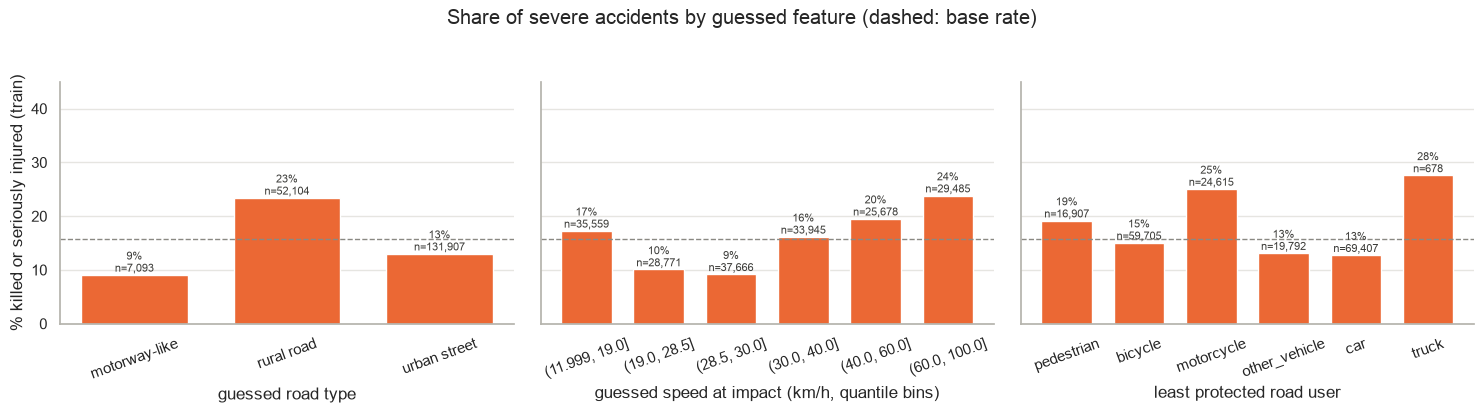

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
panels = [
    ("road_type", None, "guessed road type"),
    ("speed_guess", 6, "guessed speed at impact (km/h, quantile bins)"),
    ("least_protected_level", None, "least protected road user"),
]
level_names = {v: k for k, v in PROTECTION.items()}
for ax, (column, bins, label) in zip(axes, panels):
    groups = pd.qcut(train[column], bins, duplicates="drop") if bins else train[column]
    stats = train.groupby(groups, observed=True)[TARGET].agg(["mean", "size"])
    names = [level_names[i] for i in stats.index] if column == "least_protected_level" else stats.index.astype(str)
    ax.bar(names, stats["mean"] * 100, color=COLORS["+ guesses"], width=0.7)
    for i, (rate, n) in enumerate(zip(stats["mean"], stats["size"])):
        ax.text(i, rate * 100, f"{rate:.0%}\nn={n:,}", ha="center", va="bottom", fontsize=8, color="#3d3d3a")
    ax.axhline(base_rate * 100, color=REFERENCE, ls="--", lw=1)
    ax.set(xlabel=label, ylim=(0, 45))
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% killed or seriously injured (train)")
plt.suptitle("Share of severe accidents by guessed feature (dashed: base rate)", y=1.03)
plt.tight_layout()
plt.show()

## 4. Retrain hist gradient boosting

Same preprocessing as in `tiziano_ensembles.ipynb`, plus the guessed columns (road type one-hot encoded, the others numeric).
The hyperparameters are the tuned values from that notebook and are **identical for every feature set**, so the only
difference is the input.

Early stopping holds out a random 10 % of train, which makes the score vary by about ±0.001 between seeds. Each feature
set is therefore trained with **5 seeds**. We report the mean and spread, and score the average of the 5 models.

In [8]:
CATEGORICAL = ["state_name", "accident_kind", "accident_type", "light", "road_condition", "weekday"]
BINARY = ["bicycle", "car", "pedestrian", "motorcycle", "truck", "other_vehicle",
          "vulnerable", "single_type", "vulnerable_vs_vehicle", "is_weekend"]
NUMERIC = ["hour_sin", "hour_cos", "month_sin", "month_cos", "n_participant_types",
           "longitude", "latitude", "log_density"]
HIGH_CARDINALITY = ["district"]

GUESS_CATEGORICAL = ["road_type"]
GUESS_NUMERIC = [c for c in GUESS_COLS if c not in GUESS_CATEGORICAL]

FEATURE_SETS = {
    "base": (CATEGORICAL, NUMERIC),
    "+ guesses": (CATEGORICAL + GUESS_CATEGORICAL, NUMERIC + GUESS_NUMERIC),
    "+ guesses + random draws": (CATEGORICAL + GUESS_CATEGORICAL, NUMERIC + GUESS_NUMERIC + DRAW_COLS),
}

# tuned in tiziano_ensembles.ipynb (randomised search, 3-fold CV on train)
HGB_PARAMS = dict(learning_rate=0.0455, max_leaf_nodes=48, min_samples_leaf=176, l2_regularization=2.065,
                  max_features=0.5, max_iter=2000, early_stopping=True, n_iter_no_change=30)
SEEDS = range(5)


def make_preprocessor(categorical, numeric):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
        ("bin", "passthrough", BINARY),
        ("num", SimpleImputer(strategy="median"), numeric),
        ("te", TargetEncoder(target_type="continuous",
                             cv=KFold(5, shuffle=True, random_state=RANDOM_STATE)), HIGH_CARDINALITY),
    ], verbose_feature_names_out=False)


def columns(feature_set):
    categorical, numeric = FEATURE_SETS[feature_set]
    return categorical + BINARY + numeric + HIGH_CARDINALITY


def scores(p):
    p = np.clip(p, 0, 1)
    brier = brier_score_loss(y_val, p)
    return {"Brier": brier, "Brier skill": 1 - brier / brier_constant,
            "ROC-AUC": roc_auc_score(y_val, p), "PR-AUC": average_precision_score(y_val, p)}


brier_constant = brier_score_loss(y_val, np.full(len(y_val), base_rate))
hgb_models, hgb_pred, seed_rows = {}, {}, []
for feature_set in FEATURE_SETS:
    preds = []
    for seed in SEEDS:
        model = make_pipeline(make_preprocessor(*FEATURE_SETS[feature_set]),
                              HistGradientBoostingRegressor(random_state=seed, **HGB_PARAMS))
        model.fit(train[columns(feature_set)], y_train)
        preds.append(model.predict(val[columns(feature_set)]))
        seed_rows.append({"features": feature_set, "seed": seed, **scores(preds[-1])})
    hgb_models[feature_set] = model
    hgb_pred[feature_set] = np.mean(preds, axis=0)

per_seed = pd.DataFrame(seed_rows)
summary = per_seed.groupby("features", sort=False)[["Brier skill", "ROC-AUC", "PR-AUC"]].agg(["mean", "std"])
summary.round(4)

Brier skill         ROC-AUC          PR-AUC        
                                mean     std    mean     std    mean     std
features                                                                    
base                          0.0736  0.0004  0.7043  0.0005  0.3026  0.0011
+ guesses                     0.0743  0.0005  0.7049  0.0007  0.3038  0.0008
+ guesses + random draws      0.0736  0.0008  0.7041  0.0009  0.3029  0.0011

### Is the difference real?

The paired bootstrap resamples the validation accidents 1,000 times and recomputes the **difference in Brier skill** to
the base features on the same resample each time. If the 95 % interval contains 0, the guesses made no measurable difference.

In [9]:
def paired_bootstrap(p_new, p_ref, n=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y = y_val.to_numpy()
    p_new, p_ref = np.clip(p_new, 0, 1), np.clip(p_ref, 0, 1)
    diffs = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        constant = np.mean((y[i] - base_rate) ** 2)
        diffs.append((np.mean((y[i] - p_ref[i]) ** 2) - np.mean((y[i] - p_new[i]) ** 2)) / constant)
    return np.mean(diffs), *np.percentile(diffs, [2.5, 97.5])


rows = []
for feature_set in FEATURE_SETS:
    row = {"model": "Hist gradient boosting", "features": feature_set, **scores(hgb_pred[feature_set])}
    if feature_set != "base":
        diff, lo, hi = paired_bootstrap(hgb_pred[feature_set], hgb_pred["base"])
        row |= {"Δ Brier skill vs. base": diff, "95 % CI low": lo, "95 % CI high": hi}
    rows.append(row)
hgb_results = pd.DataFrame(rows).set_index(["model", "features"])
hgb_results.round(4)

Brier  Brier skill  ROC-AUC  \
model                  features                                                 
Hist gradient boosting base                      0.1226       0.0745   0.7055   
                       + guesses                 0.1225       0.0753   0.7062   
                       + guesses + random draws  0.1226       0.0745   0.7052   

                                                 PR-AUC  \
model                  features                           
Hist gradient boosting base                      0.3039   
                       + guesses                 0.3052   
                       + guesses + random draws  0.3041   

                                                 Δ Brier skill vs. base  \
model                  features                                           
Hist gradient boosting base                                         NaN   
                       + guesses                                 0.0007   
                       + guesses + random draws                 -0.0001   

                                                 95 % CI low  95 % CI high  
model                  features                                             
Hist gradient boosting base                              NaN           NaN  
                       + guesses                     -0.0001        0.0016  
                       + guesses + random draws      -0.0009        0.0008

## 5. Same test with linear regression

A linear model cannot build interactions such as "pedestrian *and* high speed" by itself. Guesses like `log_energy` or
`unprotected_energy` hand it exactly these interactions, so this is where the guesses should help most.

In [10]:
linear_pred, rows = {}, []
for feature_set in ["base", "+ guesses"]:
    model = make_pipeline(make_preprocessor(*FEATURE_SETS[feature_set]), LinearRegression())
    model.fit(train[columns(feature_set)], y_train)
    linear_pred[feature_set] = model.predict(val[columns(feature_set)])
    row = {"model": "Linear regression", "features": feature_set, **scores(linear_pred[feature_set])}
    if feature_set != "base":
        diff, lo, hi = paired_bootstrap(linear_pred[feature_set], linear_pred["base"])
        row |= {"Δ Brier skill vs. base": diff, "95 % CI low": lo, "95 % CI high": hi}
    rows.append(row)

results = pd.concat([pd.DataFrame(rows).set_index(["model", "features"]), hgb_results])
results.round(4)

Brier  Brier skill  ROC-AUC  \
model                  features                                                 
Linear regression      base                      0.1246       0.0590   0.6865   
                       + guesses                 0.1244       0.0606   0.6888   
Hist gradient boosting base                      0.1226       0.0745   0.7055   
                       + guesses                 0.1225       0.0753   0.7062   
                       + guesses + random draws  0.1226       0.0745   0.7052   

                                                 PR-AUC  \
model                  features                           
Linear regression      base                      0.2813   
                       + guesses                 0.2826   
Hist gradient boosting base                      0.3039   
                       + guesses                 0.3052   
                       + guesses + random draws  0.3041   

                                                 Δ Brier skill vs. base  \
model                  features                                           
Linear regression      base                                         NaN   
                       + guesses                                 0.0016   
Hist gradient boosting base                                         NaN   
                       + guesses                                 0.0007   
                       + guesses + random draws                 -0.0001   

                                                 95 % CI low  95 % CI high  
model                  features                                             
Linear regression      base                              NaN           NaN  
                       + guesses                      0.0005        0.0026  
Hist gradient boosting base                              NaN           NaN  
                       + guesses                     -0.0001        0.0016  
                       + guesses + random draws      -0.0009        0.0008

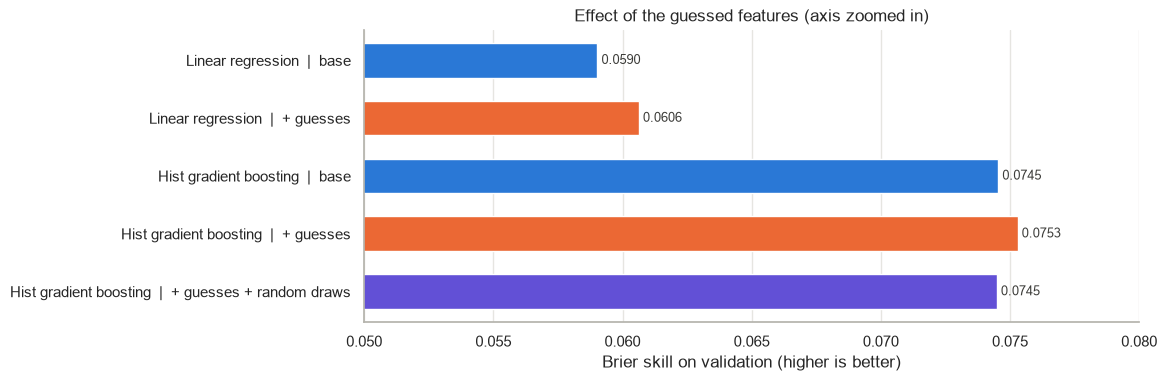

In [11]:
fig, ax = plt.subplots(figsize=(10, 3.8))
plot = results.reset_index()
labels = plot["model"] + "  |  " + plot["features"]
colors = [COLORS[f] for f in plot["features"]]
ax.barh(labels, plot["Brier skill"], color=colors, height=0.6)
for i, v in enumerate(plot["Brier skill"]):
    ax.text(v, i, f" {v:.4f}", va="center", fontsize=9, color="#3d3d3a")
ax.invert_yaxis()
ax.set(xlabel="Brier skill on validation (higher is better)", xlim=(0.05, 0.08),
       title="Effect of the guessed features (axis zoomed in)")
ax.grid(axis="y", visible=False)
plt.show()

## 6. Where does the credit go?

Permutation importance of the hist gradient boosting model with guesses, on a validation sample. Correlated features share
credit: if `speed_guess` is mostly a recoding of `accident_kind`, shuffling either one alone costs little, because the model
can fall back on the other.

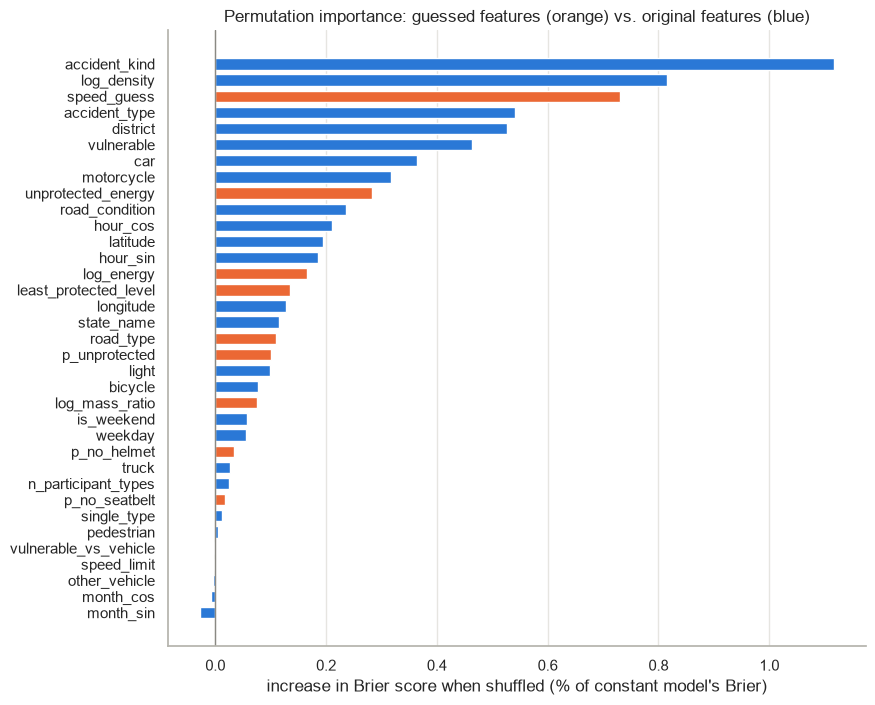

In [12]:
feature_cols = columns("+ guesses")
sample = val.sample(15_000, random_state=RANDOM_STATE)
importance = permutation_importance(
    hgb_models["+ guesses"], sample[feature_cols], y_val.loc[sample.index],
    scoring="neg_mean_squared_error", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1,
)
imp = pd.Series(importance.importances_mean, index=feature_cols).sort_values() / brier_constant * 100

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(imp.index, imp.values,
        color=[COLORS["+ guesses"] if c in GUESS_COLS else COLORS["base"] for c in imp.index], height=0.7)
ax.axvline(0, color=REFERENCE, lw=1)
ax.set(xlabel="increase in Brier score when shuffled (% of constant model's Brier)",
       title="Permutation importance: guessed features (orange) vs. original features (blue)")
ax.grid(axis="y", visible=False)
plt.show()

## 7. Summary

| model | features | Brier skill | ROC-AUC | PR-AUC | Δ Brier skill vs. base (95 % CI) |
| --- | --- | --- | --- | --- | --- |
| Linear regression | base | 0.0590 | 0.687 | 0.281 | |
| Linear regression | + guesses | 0.0606 | 0.689 | 0.283 | **+0.0016** (+0.0005 to +0.0026) |
| Hist gradient boosting | base | 0.0745 | 0.706 | 0.304 | |
| Hist gradient boosting | + guesses | 0.0753 | 0.706 | 0.305 | +0.0007 (−0.0001 to +0.0016) |
| Hist gradient boosting | + guesses + random draws | 0.0745 | 0.705 | 0.304 | −0.0001 (−0.0009 to +0.0008) |

(Hist gradient boosting: average of 5 seeds.)

* **The guesses are sensible.** Severity rises with guessed speed (from 9–10 % at 20–30 km/h to 24 % at 60–100 km/h), rural roads are
  far more dangerous than urban streets (23 % vs. 13 %), and the "motorway-like" rear-end pattern is the least severe group (9 %).
  The lowest speed bin is high (17 %) because it holds the accidents with no motor vehicle, mostly cyclists who fall on their own.
* **They barely help hist gradient boosting.** +0.0007 Brier skill, and the 95 % interval includes 0. The model ranks `speed_guess` third
  by importance, but the score hardly moves, because that importance is taken away from the columns the guess was built from
  (accident kind and type, density). The trees had already learned these patterns.
* **They help linear regression a little, and measurably** (+0.0016, interval above 0). The guesses give a linear model interactions it
  cannot build itself (speed × unprotected road user). Even so, it closes only about 10 % of the gap to hist gradient boosting.
* **Random per-accident draws add nothing.** "This cyclist wore no helmet", drawn at random, is noise; the model learns to ignore it.
  This is the general rule: a guess can only add information if it comes from somewhere the model cannot see.

**Conclusion:** educated guesses built from existing columns are useful for **explaining** the model (speed and protection are
the story stakeholders understand), but not for **improving** it. To move the score we need new information measured per accident or
location: road class and speed limit from OpenStreetMap at the accident coordinates, or weather at the time of the accident.
